# Does the start still matter after a search?

Last full run: 2026-10-23, 11 min 39 s, AMD Ryzen 7 5800, 16 workers (91 min
24 s serially on 2026-10-22, with the same results).

The 147 searches run together in a pool of worker processes
(`ariel.simulation.process_pool`, `WORKERS` of them, one per logical CPU by
default), one CMA-ES generation of each per round (`gecko_trials.lockstep`),
each told its scores in the order it asked, so the numbers are those of a
serial run.

`cpg_initialisation` compared four ways to draw a CPG's starting parameters
with no search. This notebook runs CMA-ES from each of them, 100 trials
per search and 3 seeds (0 to 2), for all seven CPGs on the
gecko with DSS-M15 hinges, and asks whether the best distance found depends
on the scheme. Each scheme is searched two ways:

* start: the search may roam each model's current ranges, as in
  `cpg_locomotion`; the scheme only gives the starting point (a draw from
  it) and the first step size (CMA-ES's `scale`, the mean share of the full
  range the scheme covers: 1 for (a) and (c), 0.75 to 0.83 for (b), and the
  mean `d - c` of the found distributions for (d)).
* bounded: the search stays inside the scheme's ranges (for (c), every
  amplitude stays under the servo's speed cap at its joint's frequency).

Scheme (a) is the same either way, and its start is the CPG's own seeded
parameters, so it is `cpg_locomotion`'s search with a smaller budget. That
gives 7 searches per CPG and seed. Scheme (d)'s distributions are the ones
`cpg_initialisation` found, copied below.

Every finished CPG appends a line to `__data__/cpg_initialisation/
progress.log`. The notebook is marked slow (about 91 minutes serially, about 12 with 16
workers);
`tools/run_notebooks.py` runs it only with `--slow` or when named.

In [1]:
# Run time: the last code cell prints how long the whole notebook took
import sys
import time

sys.stdout.write(f"Started {time.strftime('%Y-%m-%d %H:%M:%S %Z')}\n")
NOTEBOOK_STARTED = time.perf_counter()

Started 2026-10-23 17:04:57 UTC


In [2]:
# Standard library
import os
import time

# Third-party libraries
import astropy.units as u
import matplotlib.pyplot as plt
import nevergrad as ng
import numpy as np
from rich.console import Console

# Local libraries
from ariel import DATA
from ariel.parameters import DSSM15, FrozenModel, ServoSettings
from ariel.simulation import (
    AdaptiveHopfCPG,
    HopfCPG,
    LearnableTegotaeCPG,
    NaCPG,
    PhaseCPG,
    SwingStanceCPG,
    TegotaeCPG,
    process_pool,
)

%matplotlib inline
plt.rcParams["figure.dpi"] = 50  # keeps the notebook under 500 KB
console = Console()

MODELS = [
    HopfCPG,
    AdaptiveHopfCPG,
    PhaseCPG,
    SwingStanceCPG,
    NaCPG,
    TegotaeCPG,
    LearnableTegotaeCPG,
]
SCHEMES = ["a", "b", "c", "d"]
SECONDS = 10.0
STEPS_PER_CONTROL = 4
WALKS = 0.25  # metres in 10 s: a draw that moves at least this far "walks"
# The DSS-M15's speed at 6 V, the fastest a joint can follow
TOP_SPEED = ServoSettings().rating(DSSM15()).speed.to_value(u.rad / u.s)

BUDGET = 100
SEEDS = list(range(3))
WORKERS = os.cpu_count()  # pool processes; 1 runs every trial in turn

In [3]:
# The trials live in gecko_trials.py, beside this notebook: a pool worker can
# import a function from a file, never from a notebook cell
from gecko_trials import Walk, lockstep, walk, walker

## The trial and the schemes

The same trial and scheme code as `cpg_initialisation`. The trial is `Gecko.walk` from `gecko_trials.py`
beside this notebook, which the pool's worker processes import.

In [4]:
gecko = walker()
model = gecko.model
adjacency = gecko.adjacency


def trial(cpg):
    """Run one 10 s trial, as cpg_locomotion does (``Gecko.walk``).

    Returns
    -------
    float
        The distance the core travelled in the floor plane, in metres.
    """
    return gecko.walk(cpg, SECONDS)


def score(cpg_class, params):
    """Run one trial with the given flat parameters.

    Returns
    -------
    float
        The distance walked in 10 s, in metres.
    """
    cpg = cpg_class(adjacency)
    cpg.set_flat_params(np.asarray(params, dtype=np.float64))
    return trial(cpg)


OUTPUT = DATA / "cpg_initialisation"
OUTPUT.mkdir(parents=True, exist_ok=True)
PROGRESS = OUTPUT / "progress.log"


def report(line):
    """Print a line and append it to the progress log.

    The log lets a run be followed from outside while the notebook runs:
    jupyter writes the outputs only at the end.
    """
    console.print(line)
    with PROGRESS.open("a", encoding="utf-8") as log:
        log.write(f"{time.strftime('%H:%M:%S')} {line}\n")


console.print(
    f"{model.nu} actuators, timestep {model.opt.timestep * 1000:.2f} ms,"
    f" servo top speed {TOP_SPEED:.3f} rad/s"
)

8 actuators, timestep 3.75 ms, servo top speed 5.818 rad/s

In [5]:
class Shape(FrozenModel):
    """A scaled beta distribution for one parameter group (scheme d).

    Values are ``lower + (c + (d - c) * Beta(a, b)) * (upper - lower)``,
    with ``lower`` and ``upper`` the group's current range.
    """

    a: float
    b: float
    c: float
    d: float


UNIFORM = Shape(a=1.0, b=1.0, c=0.0, d=1.0)  # scheme d's start: scheme a


def slices(cpg):
    """Return the flat slice of every parameter group.

    Returns
    -------
    dict[str, slice]
        Group name to its slice of ``get_flat_params``.
    """
    out, start = {}, 0
    for name, size in cpg.group_sizes.items():
        out[name] = slice(start, start + size)
        start += size
    return out


def full_box(cpg):
    """Return the current ranges, the bounds every scheme lives in.

    Returns
    -------
    tuple[np.ndarray, np.ndarray]
        Lower and upper bound of every flat parameter.
    """
    lower, upper = cpg.parameter_bounds()
    return lower.numpy().astype(np.float64), upper.numpy().astype(np.float64)


def box(cpg, scheme, shapes):
    """Return the bounds of a scheme before scheme c's speed cap.

    Returns
    -------
    tuple[np.ndarray, np.ndarray]
        Lower and upper bound of every flat parameter.
    """
    lower, upper = full_box(cpg)
    for name, part in slices(cpg).items():
        if scheme == "b" and name.startswith("w"):
            lower[part], upper[part] = np.pi, 3 * np.pi  # 0.5 to 1.5 Hz
        elif scheme == "b" and name == "amplitudes":
            lower[part] = np.where(lower[part] < 0, -np.pi / 4, 0.0)
            upper[part] = np.pi / 4
        elif scheme == "d":
            shape = shapes.get(name, UNIFORM)
            low, high = lower[part].copy(), upper[part].copy()
            lower[part] = low + shape.c * (high - low)
            upper[part] = low + shape.d * (high - low)
    return lower, upper


def peak_rate(cpg, params):
    """Return each oscillator's fastest phase speed, in rad/s.

    Coupling and feedback are left out. A joint's peak speed is its
    amplitude times this rate.

    Returns
    -------
    np.ndarray
        One rate per joint.
    """
    part = slices(cpg)
    if isinstance(cpg, SwingStanceCPG):
        rate = np.maximum(params[part["w_swing"]], params[part["w_stance"]])
    else:
        rate = params[part["w"]].copy()
    if isinstance(cpg, NaCPG):  # the fast half turns at w / (1 - ha)
        rate /= 1 - np.abs(params[part["ha"]])
    return np.abs(rate)


def to_params(cpg, scheme, unit, shapes):
    """Map a point of the unit cube to parameters under a scheme.

    Scheme c scales each amplitude to the largest one the servo can follow
    at that joint's frequency: ``|A| * rate <= TOP_SPEED``.

    Returns
    -------
    np.ndarray
        The flat parameters.
    """
    lower, upper = box(cpg, scheme, shapes)
    params = lower + unit * (upper - lower)
    if scheme == "c":
        part = slices(cpg)["amplitudes"]
        rate = np.maximum(peak_rate(cpg, params), 1e-9)
        cap = np.minimum(upper[part], TOP_SPEED / rate)
        low = np.where(lower[part] < 0, -cap, 0.0)
        params[part] = low + unit[part] * (cap - low)
    return params


def draw_unit(cpg, scheme, rng, shapes):
    """Draw a point of the unit cube from a scheme's distribution.

    Returns
    -------
    np.ndarray
        Uniform for schemes a to c, beta per group for scheme d.
    """
    unit = rng.uniform(size=cpg.num_of_parameters)
    if scheme == "d":
        for name, part in slices(cpg).items():
            shape = shapes.get(name, UNIFORM)
            unit[part] = rng.beta(shape.a, shape.b, size=part.stop - part.start)
    return unit


def draw(cpg, scheme, rng, shapes):
    """Draw starting parameters from a scheme.

    Returns
    -------
    np.ndarray
        The flat parameters.
    """
    return to_params(cpg, scheme, draw_unit(cpg, scheme, rng, shapes), shapes)


FOUND = {
    "HopfCPG": {
        "phase": Shape(
            a=0.5647716924323343,
            b=0.8900314448146509,
            c=0.034765087209862114,
            d=0.8873864887567244,
        ),
        "w": Shape(
            a=0.890715069838923,
            b=0.21404939461778064,
            c=0.030713341005117432,
            d=0.8814455947982596,
        ),
        "amplitudes": Shape(
            a=0.9748890948587164,
            b=1.3698889835460415,
            c=0.07807035097116666,
            d=0.8952547394444511,
        ),
        "offset": Shape(
            a=0.6933183491128502,
            b=1.1211431145296573,
            c=0.13357540872014506,
            d=0.9225682317646977,
        ),
    },
    "AdaptiveHopfCPG": {
        "phase": Shape(
            a=1.3153798234608405,
            b=0.7994925740829198,
            c=0.057959094383429846,
            d=0.8331128815957378,
        ),
        "w": Shape(
            a=0.3046271098070803,
            b=0.27042785252400453,
            c=0.11291524446940744,
            d=0.9215241073610679,
        ),
        "amplitudes": Shape(
            a=1.4904140092550096,
            b=0.5776816636981849,
            c=0.1305428635748337,
            d=0.9100473532131546,
        ),
        "offset": Shape(
            a=0.6811476761342709,
            b=1.3830364876648031,
            c=0.17861335236017628,
            d=0.8176425812127261,
        ),
    },
    "PhaseCPG": {
        "phase": Shape(
            a=0.4605076682769823,
            b=1.492330359249123,
            c=0.04071376333359913,
            d=0.9905906851366246,
        ),
        "w": Shape(
            a=1.0928270952892203,
            b=1.0192938790333863,
            c=0.09148031561823405,
            d=0.9294539053643005,
        ),
        "amplitudes": Shape(
            a=1.4189783260181734,
            b=0.815828466634543,
            c=0.051652303348836553,
            d=0.9410219060597149,
        ),
        "offset": Shape(
            a=0.9836896239603955,
            b=0.9455905992534173,
            c=0.013798894110502407,
            d=0.9089887147560258,
        ),
    },
    "SwingStanceCPG": {
        "phase": Shape(
            a=0.7455439377460101,
            b=1.0039361368338429,
            c=0.059278532282475406,
            d=0.9595519170884949,
        ),
        "w_swing": Shape(
            a=1.2264639935192267,
            b=0.4572509671539613,
            c=0.08516849703141297,
            d=0.9654199746183387,
        ),
        "w_stance": Shape(
            a=0.7489743527603222,
            b=0.9319205404391055,
            c=0.05028237765949856,
            d=0.984502283243001,
        ),
        "amplitudes": Shape(
            a=1.254791397566889,
            b=0.8343132439916289,
            c=0.10938310163811933,
            d=0.9667588812387803,
        ),
        "offset": Shape(
            a=0.8293463766098353,
            b=0.5617100699434511,
            c=0.019746236852345705,
            d=0.9692875230930136,
        ),
    },
    "NaCPG": {
        "phase": Shape(
            a=0.8925550143611779,
            b=1.1073203509375025,
            c=0.03015571564229142,
            d=0.9447896392059745,
        ),
        "w": Shape(
            a=1.0570421807317154,
            b=0.7309288012115077,
            c=0.13312595674080804,
            d=0.9376069104723675,
        ),
        "amplitudes": Shape(
            a=0.6840448726211761,
            b=1.1862497090576156,
            c=0.012726764881700919,
            d=0.9878951545400829,
        ),
        "ha": Shape(
            a=1.2501238692223966,
            b=0.5793915675745527,
            c=0.03531846591669707,
            d=0.9713870509389497,
        ),
        "b": Shape(
            a=0.696792112779443,
            b=1.0244105400772392,
            c=0.014295430593372006,
            d=0.9820230750600136,
        ),
    },
    "TegotaeCPG": {
        "phase": Shape(
            a=0.9853544592609864,
            b=1.3094282840314058,
            c=0.043395238489567015,
            d=0.9002627219578044,
        ),
        "w": Shape(
            a=1.0819744832385567,
            b=0.42290477726372405,
            c=0.09655375261299404,
            d=0.8548907271786721,
        ),
        "amplitudes": Shape(
            a=0.8632694050677343,
            b=1.4651875115979842,
            c=0.04585060891500686,
            d=0.825881318963457,
        ),
        "offset": Shape(
            a=1.4409519452445363,
            b=0.897373208268608,
            c=0.018921296069307238,
            d=0.9937440406671021,
        ),
        "sigma": Shape(
            a=1.2776828887558818,
            b=0.9316195703865865,
            c=0.11807697306423628,
            d=0.9244623463467027,
        ),
    },
    "LearnableTegotaeCPG": {
        "phase": Shape(
            a=1.4001574568340176,
            b=1.1257721801795908,
            c=0.04362774710959847,
            d=0.8587649203594261,
        ),
        "w": Shape(
            a=1.6164233615963903,
            b=1.0029991997103984,
            c=0.06805770097227072,
            d=0.9834451314395096,
        ),
        "amplitudes": Shape(
            a=1.2537529520606148,
            b=1.10554894267776,
            c=0.024355124631586733,
            d=0.9384109172163269,
        ),
        "offset": Shape(
            a=1.0887261573031104,
            b=0.8545701640793488,
            c=0.012156829690145277,
            d=0.9374143672727633,
        ),
        "action": Shape(
            a=1.2233563202775208,
            b=1.042069042118187,
            c=0.12796323059036563,
            d=0.9607944626088181,
        ),
        "reaction": Shape(
            a=0.3012177184998315,
            b=1.2749816494775963,
            c=0.02342236464165158,
            d=0.9475378700971826,
        ),
        "gain": Shape(
            a=1.2582204594494106,
            b=0.5022735529350895,
            c=0.013746871623189045,
            d=0.9758256524026374,
        ),
    },
}

In [6]:
# Checks: the trial is deterministic, and FOUND holds a distribution
# with 0 <= c < d <= 1 for every group of every CPG
SAME = 1e-6  # metres
params = HopfCPG(adjacency, seed=3).get_flat_params().numpy()
assert abs(score(HopfCPG, params) - score(HopfCPG, params)) < SAME
for cpg_class in MODELS:
    name = cpg_class.__name__
    groups = set(cpg_class(adjacency).parameter_groups)
    assert set(FOUND[name]) == groups, name
    for shape in FOUND[name].values():
        assert 0 <= shape.c < shape.d <= 1, name

## The searches

In [7]:
RUNS = [("a", "start")] + [
    (scheme, mode)
    for scheme in ("b", "c", "d")
    for mode in ("start", "bounded")
]


def setup(cpg, scheme, mode, seed):
    """Choose a search's map from the unit cube, start point and step size.

    Returns
    -------
    tuple[Callable, np.ndarray, float]
        The map to parameters, the start in the unit cube, and CMA-ES's
        ``scale``.
    """
    shapes = FOUND[type(cpg).__name__] if scheme == "d" else {}
    rng = np.random.default_rng(1000 + seed)
    full_lower, full_upper = full_box(cpg)
    if scheme == "a":  # the CPG's own seeded parameters, as cpg_locomotion
        width = full_upper - full_lower
        unit = (cpg.get_flat_params().numpy() - full_lower) / width
    else:
        unit = draw_unit(cpg, scheme, rng, shapes)
    if mode == "bounded":

        def to(point):
            return to_params(cpg, scheme, point, shapes)

        start, scale = unit, 1.0
    else:

        def to(point):
            return full_lower + point * (full_upper - full_lower)

        params = to_params(cpg, scheme, unit, shapes)
        start = (params - full_lower) / (full_upper - full_lower)
        lower, upper = box(cpg, scheme, shapes)
        scale = float(np.mean((upper - lower) / (full_upper - full_lower)))
    return to, start, scale


def start(cpg_class, scheme, mode, seed):
    """Set up one CMA-ES search from a scheme.

    Returns
    -------
    tuple[ng.optimizers.base.Optimizer, Callable]
        The optimizer, and the map from its unit cube to parameters.
    """
    cpg = cpg_class(adjacency, seed=seed)
    to, start_point, scale = setup(cpg, scheme, mode, seed)
    parametrization = ng.p.Array(
        shape=(cpg.num_of_parameters,), lower=0, upper=1
    )
    parametrization.value = np.clip(start_point, 0, 1)
    parametrization.random_state = np.random.RandomState(seed)
    optimizer = ng.optimizers.ParametrizedCMA(scale=scale)(
        parametrization=parametrization, budget=BUDGET
    )
    return optimizer, to


searches = {
    (cpg_class.__name__, scheme, mode, seed): start(
        cpg_class, scheme, mode, seed
    )
    for cpg_class in MODELS
    for scheme, mode in RUNS
    for seed in SEEDS
}


def evaluate(asked):
    """Score one round of candidates in the pool.

    Returns
    -------
    list[float]
        Minus each distance, since CMA-ES minimises.
    """
    jobs = []
    for key, _, candidate in asked:
        _, to = searches[key]
        jobs.append(Walk(cpg=key[0], params=to(candidate.value).tolist()))
    walked = list(pool.map(walk, jobs))
    report(f"searches: scored {len(asked)} candidates")
    return [-distance for distance in walked]


PROGRESS.open("a", encoding="utf-8").close()
report(
    f"part 2 started: {len(MODELS)} CPGs x {len(RUNS)} searches"
    f" x {len(SEEDS)} seeds x {BUDGET} trials"
)
started = time.perf_counter()
with process_pool(WORKERS) as pool:
    told = lockstep(
        {key: optimizer for key, (optimizer, _) in searches.items()},
        BUDGET,
        evaluate,
    )
results = {}
for (name, scheme, mode, seed), (_, to) in searches.items():
    scores = np.array([-value for _, value in told[name, scheme, mode, seed]])
    first_best = int(np.argmax(scores))
    best_params = to(told[name, scheme, mode, seed][first_best][0].value)
    results.setdefault((name, scheme, mode), []).append((scores, best_params))
for cpg_class in MODELS:
    name = cpg_class.__name__
    medians = {
        run: np.median([s.max() for s, _ in results[name, *run]])
        for run in RUNS
    }
    summary = ", ".join(
        f"{s}-{m} {value:.2f}" for (s, m), value in medians.items()
    )
    report(
        f"DONE search {name} (median best of {len(SEEDS)} seeds, m): {summary}"
    )
report(
    f"DONE searches: {len(searches) * BUDGET} trials in"
    f" {time.perf_counter() - started:.0f} s on {WORKERS} workers"
)

part 2 started: 7 CPGs x 7 searches x 3 seeds x 100 trials

searches: scored 2184 candidates

searches: scored 2184 candidates

searches: scored 2184 candidates

searches: scored 2184 candidates

...

DONE search SwingStanceCPG (median best of 3 seeds, m): a-start 0.86, b-start 0.41, b-bounded 0.44, c-start 0.30, 
c-bounded 0.21, d-start 0.61, d-bounded 0.62

DONE search NaCPG (median best of 3 seeds, m): a-start 0.79, b-start 0.66, b-bounded 0.68, c-start 0.70, c-bounded 
0.69, d-start 0.67, d-bounded 1.00

DONE search TegotaeCPG (median best of 3 seeds, m): a-start 0.25, b-start 0.38, b-bounded 0.33, c-start 0.29, 
c-bounded 0.43, d-start 0.41, d-bounded 0.37

DONE search LearnableTegotaeCPG (median best of 3 seeds, m): a-start 0.48, b-start 0.50, b-bounded 0.48, c-start 
0.54, c-bounded 0.45, d-start 0.36, d-bounded 0.32

DONE searches: 14700 trials in 694 s on 16 workers

In [8]:
# Checks: every search ran its budget with finite distances; its best
# parameters lie inside the current ranges, and a bounded search's
# inside its scheme's ranges
for cpg_class in MODELS:
    name = cpg_class.__name__
    cpg = cpg_class(adjacency)
    full_lower, full_upper = full_box(cpg)
    for scheme, mode in RUNS:
        shapes = FOUND[name] if scheme == "d" else {}
        lower, upper = box(cpg, scheme, shapes)
        for scores, params in results[name, scheme, mode]:
            assert len(scores) == BUDGET, (name, scheme, mode)
            assert np.isfinite(scores).all(), (name, scheme, mode)
            assert (params >= full_lower - SAME).all(), (name, scheme, mode)
            assert (params <= full_upper + SAME).all(), (name, scheme, mode)
            if mode == "bounded":
                assert (params >= lower - SAME).all(), (name, scheme, mode)
                assert (params <= upper + SAME).all(), (name, scheme, mode)

## Results

Best distance so far against the number of trials, median of the seeds,
for every scheme and mode; one panel per CPG.

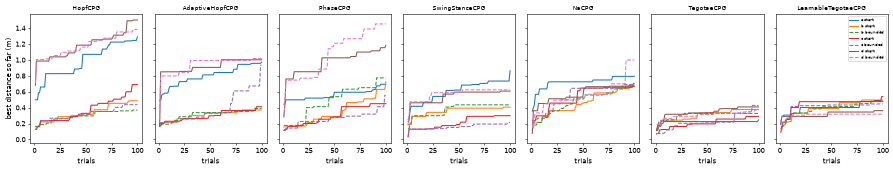

CPG                      a-start     b-start   b-bounded     c-start   c-bounded     d-start   d-bounded

HopfCPG               1.29(0.91)  0.49(0.38)  0.37(0.35)  0.69(0.35)  0.44(0.44)  1.50(0.81)  1.38(0.65)

AdaptiveHopfCPG       0.97(0.86)  0.37(0.34)  0.39(0.33)  0.41(0.29)  0.93(0.37)  1.00(0.32)  1.02(0.28)

PhaseCPG              0.69(0.59)  0.73(0.26)  0.77(0.25)  0.45(0.25)  0.56(0.29)  1.18(0.99)  1.45(1.40)

SwingStanceCPG        0.86(0.70)  0.41(0.33)  0.44(0.39)  0.30(0.13)  0.21(0.10)  0.61(0.51)  0.62(0.40)

NaCPG                 0.79(0.50)  0.66(0.51)  0.68(0.66)  0.70(0.43)  0.69(0.65)  0.67(0.55)  1.00(0.48)

TegotaeCPG            0.25(0.22)  0.38(0.28)  0.33(0.28)  0.29(0.27)  0.43(0.15)  0.41(0.10)  0.37(0.14)

LearnableTegotaeCPG   0.48(0.40)  0.50(0.33)  0.48(0.41)  0.54(0.39)  0.45(0.43)  0.36(0.24)  0.32(0.22)

cells: median of the seeds' best distance, worst seed in brackets (m)

In [9]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(18, 3.5), sharey=True)
trials = np.arange(1, BUDGET + 1)
for ax, cpg_class in zip(axes, MODELS, strict=True):
    name = cpg_class.__name__
    for scheme, mode in RUNS:
        curves = np.array([
            np.maximum.accumulate(s) for s, _ in results[name, scheme, mode]
        ])
        ax.plot(
            trials,
            np.median(curves, axis=0),
            linestyle="-" if mode == "start" else "--",
            label=f"{scheme} {mode}",
        )
    ax.set_title(name, fontsize=8)
    ax.set_xlabel("trials")
axes[0].set_ylabel("best distance so far (m)")
axes[-1].legend(fontsize=6)
fig.tight_layout()
plt.show()

console.print(f"{'CPG':20s}" + "".join(f" {s + '-' + m:>11s}" for s, m in RUNS))
for cpg_class in MODELS:
    name = cpg_class.__name__
    cells_ = []
    for scheme, mode in RUNS:
        best = np.array([s.max() for s, _ in results[name, scheme, mode]])
        cells_.append(f" {np.median(best):5.2f}({best.min():.2f})")
    console.print(f"{name:20s}" + "".join(cells_))
console.print(
    "cells: median of the seeds' best distance, worst seed in brackets (m)"
)

In [10]:
# Checks: a search's best parameters walk as far when run again
scores, params = results["PhaseCPG", "a", "start"][0]
assert abs(score(PhaseCPG, params) - scores.max()) < SAME

# Run time of the whole notebook; after a full run, copy it into the
# "Last full run" line under the title
minutes, seconds = divmod(round(time.perf_counter() - NOTEBOOK_STARTED), 60)
report(f"Total run time: {minutes} min {seconds} s")

Total run time: 11 min 39 s

## Conclusions

From the run of 2026-10-23 on the DSS-M15 hinges (100 trials per search, 3
seeds; numbers from the table above, median of the seeds' best and worst
seed), which printed exactly the numbers of the serial run of 2026-10-22.
With 3 seeds, gaps under about 0.1 m are noise.

1. The start still matters after 100 trials, as much as the choice of CPG:
   `PhaseCPG` reaches 0.69 m from the current ranges (a) and 1.45 m inside
   its searched distributions (d, bounded), with a worst seed of 1.40 m.
2. The searched distributions (d) give the best result for `HopfCPG` (1.50
   against 1.29 m), `PhaseCPG` (1.45 against 0.69 m) and `NaCPG` (1.00
   against 0.79 m, bounded only), tie for `AdaptiveHopfCPG`, and lose for
   `SwingStanceCPG` (0.62 against 0.86 m) and `LearnableTegotaeCPG` (0.36
   against 0.48 m), the two whose distribution search gained least in
   `cpg_initialisation`. They also vary more between seeds: `AdaptiveHopfCPG`
   from (d) has a worst seed of 0.28 m, from (a) 0.86 m. A narrow
   distribution helps when it sits on good gaits and strands a seed when it
   does not.
3. The current ranges (a) are the most reliable start: the best worst seed
   for `HopfCPG` (0.91 m), `AdaptiveHopfCPG` (0.86 m) and `SwingStanceCPG`
   (0.70 m).
4. Narrow (b) and servo-safe (c) starts rarely help and often hurt: for
   `HopfCPG`, `AdaptiveHopfCPG` and `SwingStanceCPG` they end at 0.21 to
   0.69 m against 0.86 to 1.29 m from (a), even when the search may leave
   their ranges (one exception: `AdaptiveHopfCPG` bounded to (c), 0.93 m). Their poorer start and smaller first step (CMA-ES `scale`
   below 1 for (b)) compound in 100 trials. Only the two Tegotae models,
   whose searches all stay short (0.25 to 0.54 m), do not lose by them.
5. Bounding the search to the scheme's ranges has no consistent effect,
   except for (d), where it helps `PhaseCPG` (1.18 to 1.45 m) and `NaCPG`
   (0.67 to 1.00 m): staying inside a good distribution pays when the
   distribution is good.

So: keep the current ranges as the default start. A searched distribution
is worth it for the Hopf, phase and NA-CPG models, once its search scores
each candidate on more than 4 draws (`cpg_initialisation`, conclusion 3).
Do not limit the starting amplitudes to what the servo can follow: the
search finds better gaits from outside that region.